# Part 2 (notebook 2): Run 1, LoRA rank 4

Run `p2_baseline.ipynb` first (notebook 1): this notebook reads the cleaned data, the 20 fixed prompts, the sampler settings and the base-model results that it saved.

| | |
|---|---|
| Base model | Stable Diffusion 1.5 (same as baseline and Run 2) |
| Method | LoRA, rank 4, alpha 4, on UNet attention layers (q, k, v, out) |
| Budget | 3000 steps, batch 4, lr 1e-4 (cosine, 100 warmup), seed 266 (same for Run 2) |

**LoRA** (Hu et al., 2021) freezes the original weight *W* and learns a small update *ΔW = B·A*, where *A* and *B* have rank *r = 4*. Only *A* and *B* are trained, which is under 1% of the UNet.

In [7]:
%pip install -q diffusers==0.31.0 transformers==4.46.3 peft==0.13.2 accelerate==1.1.1 datasets==3.1.0 huggingface_hub==0.26.2 torchmetrics==1.6.0 torch-fidelity==0.3.0 lpips==0.1.4

In [8]:
import subprocess, platform, random, os
import numpy as np, torch, diffusers, transformers, peft, torchmetrics, datasets

SEED = 266
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

try:
    commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], text=True).strip()
except Exception:
    commit = "no git repo here"

print("commit      ", commit)
print("python      ", platform.python_version())
for m in [torch, diffusers, transformers, peft, torchmetrics, datasets]:
    print(f"{m.__name__:12s}", m.__version__)
print("gpu         ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")
print("seed        ", SEED)

commit       no git repo here
python       3.13.16
torch        2.14.1+cu130
diffusers    0.31.0
transformers 4.46.3
peft         0.13.2
torchmetrics 1.6.0
datasets     3.1.0
gpu          Tesla T4
seed         266


In [9]:
import json, time, gc, textwrap
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [10]:
from huggingface_hub import HfApi, login
from transformers import CLIPTokenizer, CLIPTextModel, CLIPImageProcessor
from diffusers import StableDiffusionPipeline, UNet2DConditionModel, AutoencoderKL, DDPMScheduler, DPMSolverMultistepScheduler
from diffusers.optimization import get_scheduler
from diffusers.training_utils import cast_training_params
from diffusers.utils import convert_state_dict_to_diffusers
from diffusers.pipelines.stable_diffusion.safety_checker import StableDiffusionSafetyChecker
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from torchmetrics.image.kid import KernelInceptionDistance
from torchmetrics.multimodal.clip_score import CLIPScore
import lpips

In [11]:
device = "cuda"
BASE = "stable-diffusion-v1-5/stable-diffusion-v1-5"
RES = 512
RUN = "run1"
RANK = 4
STEPS = 3000
BATCH = 4
LR = 1e-4
RETRAIN = False
REUSE = True
HF_USER = "your-hf-username"
UPLOAD = False

In [12]:
IN_COLAB = "google.colab" in str(get_ipython())
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/data266-lab2")
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EVAL = ROOT / "eval"
WORK = ROOT / "work"
DATA = WORK / "p2_data"
RUN_DIR = WORK / "p2_runs" / RUN
GEN_DIR = WORK / "p2_gen"
LOGS = ROOT / "logs"
for d in [EVAL, RUN_DIR, GEN_DIR, LOGS]:
    d.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [13]:
LOG_FILE = LOGS / "p2_run_log.txt"
TRAIN_LOG = LOGS / f"{RUN}_train_log.txt"

def log(*args, file=LOG_FILE):
    line = time.strftime("%Y-%m-%d %H:%M:%S") + " | " + " ".join(str(a) for a in args)
    print(line)
    with open(file, "a") as f:
        f.write(line + "\n")

log("=" * 60)
log(f"{RUN} notebook | rank {RANK} | seed", SEED, "| gpu", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

2026-11-10 02:41:08 | ============================================================
2026-11-10 02:41:10 | run1 notebook | rank 4 | seed 266 | gpu Tesla T4


## Load what the baseline notebook saved

In [14]:
needed = [DATA / "train_clean.csv", DATA / "test.csv", EVAL / "p2_prompts.json", EVAL / "p2_sampler.json",
          EVAL / "p2_baseline_results.csv", GEN_DIR / "base_metadata.csv", GEN_DIR / "base_lpips.csv"]
for f in needed:
    print(f"{'ok ' if f.exists() else 'MISSING'}  {f}")
assert all(f.exists() for f in needed), "run p2_baseline.ipynb first"

ok   /content/drive/MyDrive/data266-lab2/work/p2_data/train_clean.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_data/test.csv
ok   /content/drive/MyDrive/data266-lab2/eval/p2_prompts.json
ok   /content/drive/MyDrive/data266-lab2/eval/p2_sampler.json
ok   /content/drive/MyDrive/data266-lab2/eval/p2_baseline_results.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_gen/base_metadata.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_gen/base_lpips.csv


In [15]:
train_df = pd.read_csv(DATA / "train_clean.csv")
test_df = pd.read_csv(DATA / "test.csv")
prompts = json.loads((EVAL / "p2_prompts.json").read_text())
sampler = json.loads((EVAL / "p2_sampler.json").read_text())
baseline = pd.read_csv(EVAL / "p2_baseline_results.csv", index_col=0)["base"]
base = pd.read_csv(GEN_DIR / "base_metadata.csv")
base_div = pd.read_csv(GEN_DIR / "base_lpips.csv")
print("train", len(train_df), "| test", len(test_df), "| prompts", len(prompts), "| sampler", sampler)

train 859 | test 123 | prompts 20 | sampler {'scheduler': 'DPMSolverMultistepScheduler', 'num_inference_steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512}


## 2.2 Training Run 1

One training step:
1. Encode the image to a 64×64×4 latent with the frozen VAE.
2. Encode the caption with the frozen CLIP text encoder.
3. Add random noise at a random timestep *t*.
4. The UNet (with LoRA) predicts that noise.
5. Loss = MSE between the predicted and the real noise. Only the LoRA weights are updated.

Memory savers: fp16 base weights, fp32 LoRA weights, gradient checkpointing, mixed precision.

`RETRAIN = False` reloads the adapter already saved in Drive and prints its saved training log. Set it to `True` to train again (about 75 min on a T4).

In [16]:
TRAINED = (RUN_DIR / "stats.json").exists() and (RUN_DIR / "pytorch_lora_weights.safetensors").exists()
DO_TRAIN = RETRAIN or not TRAINED
print("adapter saved in Drive:", TRAINED, "| train now:", DO_TRAIN)

adapter saved in Drive: False | train now: True


In [17]:
tokenizer = CLIPTokenizer.from_pretrained(BASE, subfolder="tokenizer")
if DO_TRAIN:
    text_encoder = CLIPTextModel.from_pretrained(BASE, subfolder="text_encoder", torch_dtype=torch.float16).to(device)
    vae = AutoencoderKL.from_pretrained(BASE, subfolder="vae", torch_dtype=torch.float16).to(device)
    noise_sched = DDPMScheduler.from_pretrained(BASE, subfolder="scheduler")
    text_encoder.requires_grad_(False)
    vae.requires_grad_(False)
    print("frozen: text encoder + VAE")
else:
    print("not training: text encoder and VAE not loaded")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

frozen: text encoder + VAE


In [18]:
class NarutoTrain(Dataset):
    def __init__(self, df):
        self.df = df
        self.tf = transforms.Compose([
            transforms.RandomHorizontalFlip(),
            transforms.ToTensor(),
            transforms.Normalize([0.5], [0.5]),
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        ids = tokenizer(r.text, padding="max_length", max_length=tokenizer.model_max_length,
                        truncation=True, return_tensors="pt").input_ids[0]
        return {"pixel_values": self.tf(Image.open(r.file).convert("RGB")), "input_ids": ids}

In [19]:
train_ds = NarutoTrain(train_df)
len(train_ds)

859

In [20]:
def make_lora_unet(rank):
    torch.manual_seed(SEED)
    unet = UNet2DConditionModel.from_pretrained(BASE, subfolder="unet", torch_dtype=torch.float16).to(device)
    unet.requires_grad_(False)
    unet.add_adapter(LoraConfig(r=rank, lora_alpha=rank, init_lora_weights="gaussian",
                                target_modules=["to_k", "to_q", "to_v", "to_out.0"]))
    cast_training_params(unet, dtype=torch.float32)
    unet.enable_gradient_checkpointing()
    return unet

In [21]:
def train(unet, steps=STEPS, lr=LR, bs=BATCH):
    params = [p for p in unet.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(params, lr=lr, weight_decay=1e-2)
    lr_sched = get_scheduler("cosine", opt, num_warmup_steps=100, num_training_steps=steps)
    scaler = torch.amp.GradScaler("cuda")
    loader = DataLoader(train_ds, batch_size=bs, shuffle=True, drop_last=True, num_workers=2,
                        generator=torch.Generator().manual_seed(SEED))

    log(f"{RUN} start | steps {steps} | batch {bs} | lr {lr} | trainable {sum(p.numel() for p in params):,}", file=TRAIN_LOG)
    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    t0 = time.time()
    losses = []
    step = 0
    unet.train()

    while step < steps:
        for batch in loader:
            with torch.no_grad():
                lat = vae.encode(batch["pixel_values"].to(device, torch.float16)).latent_dist.sample()
                lat = lat * vae.config.scaling_factor
                enc = text_encoder(batch["input_ids"].to(device))[0]

            noise = torch.randn_like(lat)
            t = torch.randint(0, noise_sched.config.num_train_timesteps, (lat.shape[0],), device=device).long()
            noisy = noise_sched.add_noise(lat, noise, t)

            with torch.autocast("cuda", dtype=torch.float16):
                pred = unet(noisy, t, enc).sample
            loss = F.mse_loss(pred.float(), noise.float())

            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(params, 1.0)
            scaler.step(opt)
            scaler.update()
            lr_sched.step()
            opt.zero_grad(set_to_none=True)

            losses.append(loss.item())
            step += 1
            if step % 250 == 0:
                mem = torch.cuda.max_memory_allocated() / 1024 ** 3
                log(f"{RUN} step {step}/{steps} | loss {np.mean(losses[-250:]):.4f} | lr {lr_sched.get_last_lr()[0]:.2e} | "
                    f"{(time.time() - t0) / 60:.1f} min | peak {mem:.2f} GB", file=TRAIN_LOG)
            if step >= steps:
                break

    torch.cuda.synchronize()
    log(f"{RUN} done | {(time.time() - t0) / 60:.1f} min | peak {torch.cuda.max_memory_allocated() / 1024 ** 3:.2f} GB", file=TRAIN_LOG)
    return {
        "rank": RANK,
        "trainable_params": sum(p.numel() for p in params),
        "lr": lr, "steps": steps, "batch_size": bs,
        "peak_mem_gb": torch.cuda.max_memory_allocated() / 1024 ** 3,
        "train_sec": time.time() - t0,
        "gpu": torch.cuda.get_device_name(0),
        "losses": losses,
    }

In [22]:
def save_run(unet, stats):
    lora_sd = convert_state_dict_to_diffusers(get_peft_model_state_dict(unet))
    StableDiffusionPipeline.save_lora_weights(RUN_DIR, unet_lora_layers=lora_sd, safe_serialization=True)
    (RUN_DIR / "stats.json").write_text(json.dumps(stats))

In [23]:
if not DO_TRAIN:
    stats = json.loads((RUN_DIR / "stats.json").read_text())
    print(f"loaded saved {RUN} from {RUN_DIR}\n")
    print(TRAIN_LOG.read_text() if TRAIN_LOG.exists() else "no saved training log")
else:
    unet = make_lora_unet(RANK)
    stats = train(unet)
    save_run(unet, stats)
    del unet
    gc.collect()
    torch.cuda.empty_cache()

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

2026-11-10 02:42:21 | run1 start | steps 3000 | batch 4 | lr 0.0001 | trainable 797,184
2026-11-10 02:49:12 | run1 step 250/3000 | loss 0.0914 | lr 9.93e-05 | 6.8 min | peak 3.54 GB
2026-11-10 02:55:32 | run1 step 500/3000 | loss 0.0931 | lr 9.54e-05 | 13.2 min | peak 3.54 GB
2026-11-10 03:01:51 | run1 step 750/3000 | loss 0.0881 | lr 8.81e-05 | 19.5 min | peak 3.54 GB
2026-11-10 03:08:11 | run1 step 1000/3000 | loss 0.0911 | lr 7.81e-05 | 25.8 min | peak 3.54 GB
2026-11-10 03:14:31 | run1 step 1250/3000 | loss 0.0907 | lr 6.60e-05 | 32.2 min | peak 3.54 GB
2026-11-10 03:20:52 | run1 step 1500/3000 | loss 0.0942 | lr 5.27e-05 | 38.5 min | peak 3.54 GB
2026-11-10 03:27:12 | run1 step 1750/3000 | loss 0.0919 | lr 3.93e-05 | 44.8 min | peak 3.54 GB
2026-11-10 03:33:32 | run1 step 2000/3000 | loss 0.0899 | lr 2.66e-05 | 51.2 min | peak 3.54 GB
2026-11-10 03:39:53 | run1 step 2250/3000 | loss 0.0938 | lr 1.56e-05 | 57.5 min | peak 3.54 GB
2026-11-10 03:46:12 | run1 step 2500/3000 | loss 0.0

In [24]:
sorted(p.name for p in RUN_DIR.iterdir())

['pytorch_lora_weights.safetensors', 'stats.json']

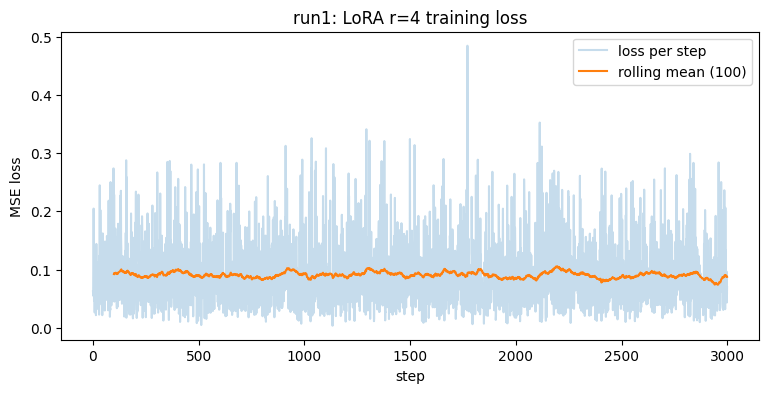

In [25]:
plt.figure(figsize=(9, 4))
plt.plot(stats["losses"], alpha=0.25, label="loss per step")
plt.plot(pd.Series(stats["losses"]).rolling(100).mean(), label="rolling mean (100)")
plt.xlabel("step")
plt.ylabel("MSE loss")
plt.title(f"{RUN}: LoRA r={RANK} training loss")
plt.legend()
plt.show()

### Training table (Run 1)

In [26]:
train_row = pd.Series({
    "method": f"LoRA r={stats['rank']}",
    "trainable_params": f"{stats['trainable_params']:,}",
    "learning_rate": stats["lr"],
    "steps": stats["steps"],
    "batch_size": stats["batch_size"],
    "peak_gpu_mem_GB": round(stats["peak_mem_gb"], 2),
    "train_time_min": round(stats["train_sec"] / 60, 1),
    "gpu_hours": round(stats["train_sec"] / 3600, 3),
    "gpu": stats["gpu"],
}, name=RUN)
train_row.to_frame().to_csv(EVAL / f"p2_{RUN}_training.csv")
log(f"{RUN} | " + " | ".join(f"{k} {v}" for k, v in train_row.items()))
train_row.to_frame()

2026-11-10 03:58:54 | run1 | method LoRA r=4 | trainable_params 797,184 | learning_rate 0.0001 | steps 3000 | batch_size 4 | peak_gpu_mem_GB 3.54 | train_time_min 76.5 | gpu_hours 1.275 | gpu Tesla T4


,run1
method,LoRA r=4
trainable_params,"797,184"
learning_rate,0.0001
steps,3000
batch_size,4
peak_gpu_mem_GB,3.54
train_time_min,76.5
gpu_hours,1.275
gpu,Tesla T4


In [27]:
repo = f"{HF_USER}/naruto-sd15-lora-r{RANK}"
if UPLOAD:
    from google.colab import userdata
    login(token=userdata.get("HF_TOKEN"))
    api = HfApi()
    api.create_repo(repo, private=True, exist_ok=True)
    api.upload_folder(repo_id=repo, folder_path=RUN_DIR, allow_patterns=["*.safetensors", "stats.json"])
    log("uploaded", RUN, "->", f"https://huggingface.co/{repo}")
else:
    print("UPLOAD is False: adapter saved only in", RUN_DIR)

UPLOAD is False: adapter saved only in /content/drive/MyDrive/data266-lab2/work/p2_runs/run1


## 2.3 Generation with Run 1

Same prompts, seeds (0 and 1) and sampler settings as the baseline, so the only difference from the base images is the LoRA adapter.

In [28]:
if DO_TRAIN:
    del text_encoder, vae
gc.collect()
torch.cuda.empty_cache()

In [29]:
GEN = {k: v for k, v in sampler.items() if k != "scheduler"}
META_FILE = GEN_DIR / f"{RUN}_metadata.csv"
GEN_STATS = GEN_DIR / f"{RUN}_gen_stats.json"
GEN_CACHED = False
if REUSE and not DO_TRAIN and META_FILE.exists() and GEN_STATS.exists():
    gen = pd.read_csv(META_FILE)
    GEN_CACHED = len(gen) == 40 and all(Path(f).exists() for f in gen.file)
print("reuse saved", RUN, "images from Drive:", GEN_CACHED, "| sampler", GEN)

reuse saved run1 images from Drive: False | sampler {'num_inference_steps': 30, 'guidance_scale': 7.5, 'height': 512, 'width': 512}


In [30]:
if not GEN_CACHED:
    pipe = StableDiffusionPipeline.from_pretrained(BASE, torch_dtype=torch.float16, safety_checker=None,
                                                   requires_safety_checker=False).to(device)
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    pipe.load_lora_weights(str(RUN_DIR))

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

In [31]:
if GEN_CACHED:
    gen_peak = json.loads(GEN_STATS.read_text())["peak_gb"]
    print("loaded", len(gen), RUN, "images from", GEN_DIR)
else:
    torch.cuda.reset_peak_memory_stats()
    rows = []
    for p in prompts:
        for seed in (0, 1):
            path = GEN_DIR / f"{RUN}_p{p['id']:02d}_s{seed}.png"
            t0 = time.time()
            img = pipe(p["prompt"], generator=torch.Generator(device).manual_seed(seed), **GEN).images[0]
            sec = time.time() - t0
            img.save(path)
            rows.append({"model": RUN, "prompt_id": p["id"], "category": p["category"],
                         "prompt": p["prompt"], "seed": seed, "file": str(path), "sec": sec})
    gen = pd.DataFrame(rows)
    gen_peak = torch.cuda.max_memory_allocated() / 1024 ** 3
    gen.to_csv(META_FILE, index=False)
    GEN_STATS.write_text(json.dumps({"peak_gb": gen_peak, "version": 2}))
    log(f"{RUN} generation |", len(gen), "images | median sec/img", round(gen.sec.median(), 2))
print("images:", len(gen), "| median sec/img %.2f | peak GPU mem %.2f GB" % (gen.sec.median(), gen_peak))

2026-11-10 04:02:34 | run1 generation | 40 images | median sec/img 4.99
images: 40 | median sec/img 4.99 | peak GPU mem 2.62 GB


In [32]:
def show_pairs(ids, seed=0, title=None):
    fig, axes = plt.subplots(len(ids), 2, figsize=(7, 3.4 * len(ids)))
    for r, pid in enumerate(ids):
        for c, df in enumerate([base, gen]):
            f = df[(df.prompt_id == pid) & (df.seed == seed)].file.iloc[0]
            axes[r, c].imshow(Image.open(f))
            axes[r, c].set_xticks([])
            axes[r, c].set_yticks([])
            if r == 0:
                axes[r, c].set_title(["base", RUN][c], fontsize=12)
        axes[r, 0].set_ylabel(textwrap.fill(f"[{pid}] {prompts[pid]['prompt']}", 26), fontsize=8)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()

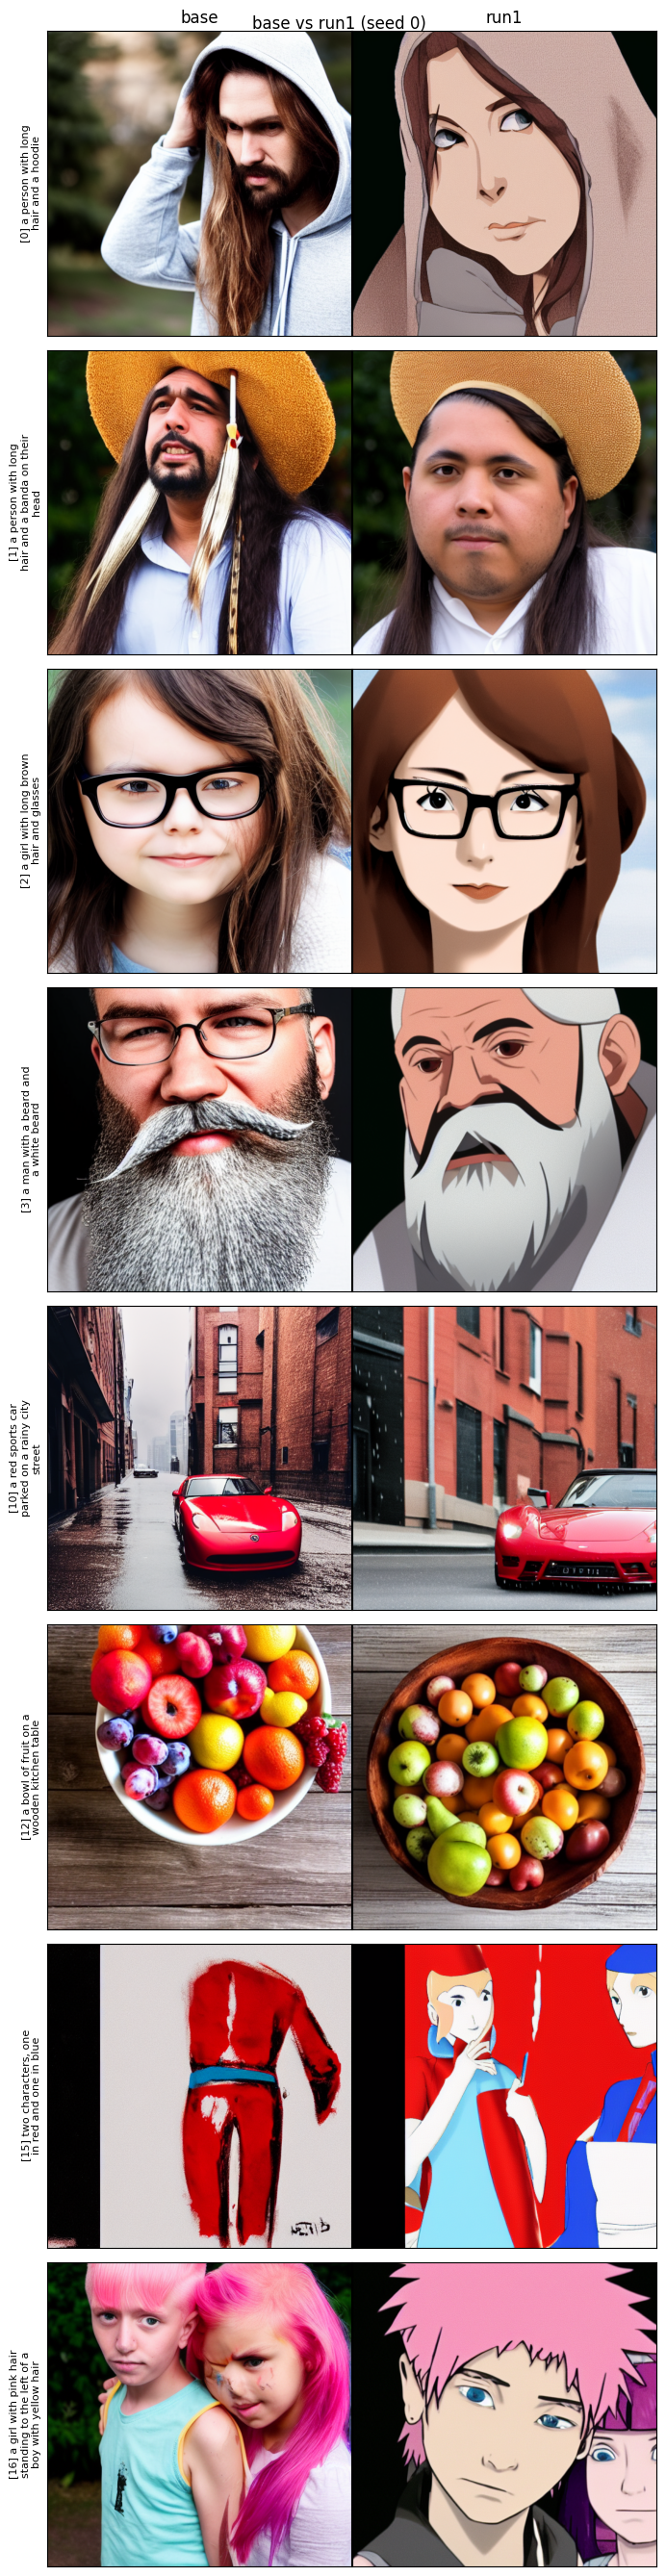

In [33]:
grid_ids = [0, 1, 2, 3, 10, 12, 15, 16]
show_pairs(grid_ids, title=f"base vs {RUN} (seed 0)")

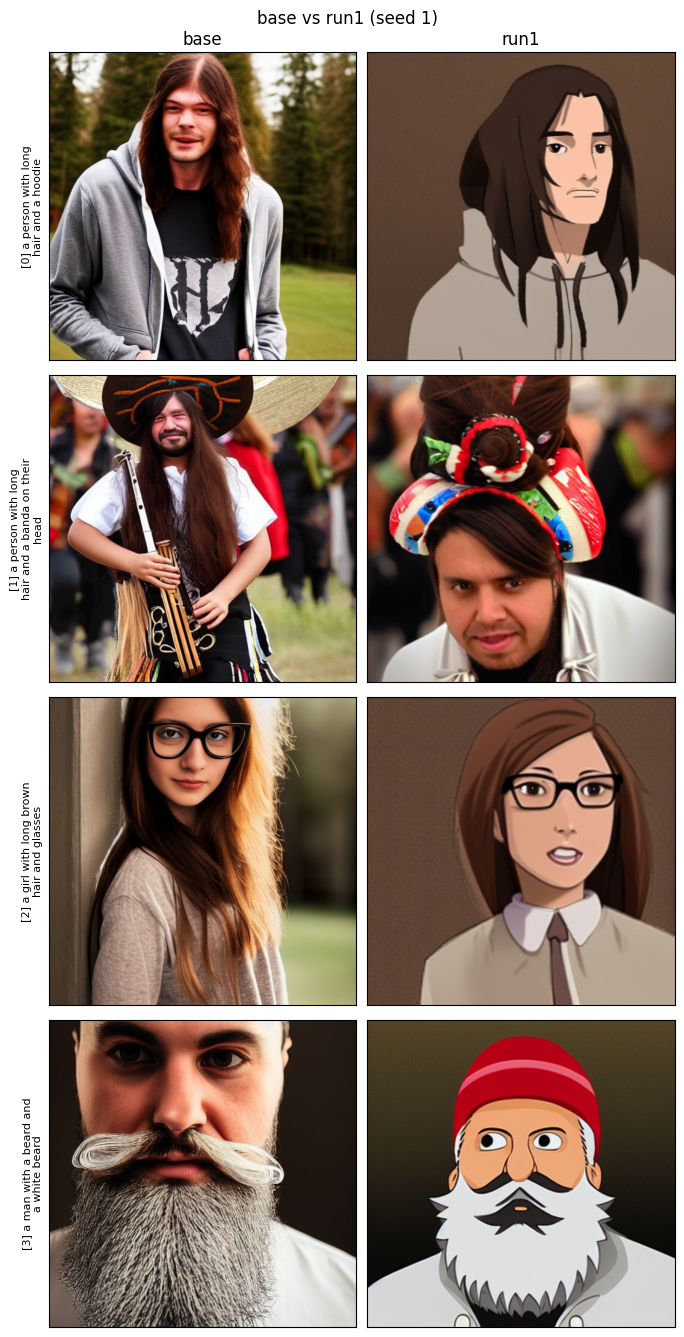

In [34]:
show_pairs(grid_ids[:4], seed=1, title=f"base vs {RUN} (seed 1)")

## 2.4 Metrics for Run 1

In [35]:
def load_uint8(files, size=None):
    ims = [Image.open(f).convert("RGB") for f in files]
    if size:
        ims = [im.resize((size, size), Image.BICUBIC) for im in ims]
    return torch.from_numpy(np.stack([np.asarray(im) for im in ims])).permute(0, 3, 1, 2)

In [36]:
real = load_uint8(test_df.file, 299)
fake = load_uint8(gen[gen.category == "in_domain"].file, 299)
real.shape, fake.shape

(torch.Size([123, 3, 299, 299]), torch.Size([20, 3, 299, 299]))

In [37]:
kid = KernelInceptionDistance(subset_size=min(len(fake), len(real)), subsets=100).to(device)
torch.manual_seed(SEED)
for k in range(0, len(real), 32):
    kid.update(real[k:k + 32].to(device), real=True)
kid.update(fake.to(device), real=False)
kid_mu, kid_sd = [v.item() for v in kid.compute()]
log(f"{RUN} KID = {kid_mu:.4f} ± {kid_sd:.4f} (base was {baseline['KID in-domain (lower better)']:.4f})")

/usr/local/lib/python3.13/dist-packages/torchmetrics/utilities/prints.py:43: UserWarning: Metric `Kernel Inception Distance` will save all extracted features in buffer. For large datasets this may lead to large memory footprint.
  warnings.warn(*args, **kwargs)  # noqa: B028
Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 305MB/s]


2026-11-10 04:04:35 | run1 KID = 0.0389 ± 0.0077 (base was 0.1337)


In [38]:
clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch16").to(device)

scores = []
for r in gen.itertuples():
    scores.append(clip_metric(load_uint8([r.file])[0].to(device), r.prompt).item())
    clip_metric.reset()
gen["clip"] = scores

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

In [39]:
clip_cmp = pd.DataFrame({"base": base.groupby("category").clip.mean(), RUN: gen.groupby("category").clip.mean()})
clip_cmp[f"{RUN} - base"] = clip_cmp[RUN] - clip_cmp["base"]
clip_cmp.round(2)

,base,run1,run1 - base
category,,,
compositional,31.46,32.35,0.88
in_domain,31.19,29.25,-1.95
ood,32.31,30.57,-1.75


In [40]:
lp = lpips.LPIPS(net="alex").to(device)

def to_lp(f):
    x = np.asarray(Image.open(f).convert("RGB"), dtype=np.float32) / 127.5 - 1
    return torch.from_numpy(x).permute(2, 0, 1)[None].to(device)

Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 160MB/s]


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/alex.pth


In [41]:
div = []
for pid, g in gen.groupby("prompt_id"):
    a, b = g.sort_values("seed").file.tolist()
    with torch.no_grad():
        d = lp(to_lp(a), to_lp(b)).item()
    div.append({"model": RUN, "prompt_id": pid, "category": g.category.iloc[0], "lpips": d})
div = pd.DataFrame(div)
pd.DataFrame({"base": base_div.groupby("category").lpips.mean(), RUN: div.groupby("category").lpips.mean()}).round(3)

,base,run1
category,,
compositional,0.842,0.793
in_domain,0.803,0.772
ood,0.784,0.765


In [42]:
safety = None
safety_proc = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")

def nsfw_flags(paths, bs=32):
    global safety
    if safety is None:
        safety = StableDiffusionSafetyChecker.from_pretrained("CompVis/stable-diffusion-safety-checker").to(device)
    flags = []
    for k in range(0, len(paths), bs):
        ims = [Image.open(p).convert("RGB") for p in paths[k:k + bs]]
        clip_in = safety_proc(ims, return_tensors="pt").pixel_values.to(device)
        arr = np.stack([np.asarray(im, dtype=np.float32) / 255 for im in ims])
        _, has = safety(images=arr, clip_input=clip_in)
        flags += [bool(h) for h in has]
    return flags

if "nsfw" not in gen.columns:
    gen["nsfw"] = nsfw_flags(gen.file.tolist())
print(f"{RUN} generations flagged NSFW:", int(gen.nsfw.sum()), "/", len(gen))
gen[gen.nsfw][["prompt_id", "seed", "category", "prompt"]]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


run1 generations flagged NSFW: 2 / 40


,prompt_id,seed,category,prompt
10,5,0,in_domain,a man with glasses and a white shirt
15,7,1,in_domain,a man with a baseball cap on his head


## Results: base vs Run 1

In [44]:
run_res = pd.Series({
    "KID in-domain (lower better)": kid_mu,
    "KID std": kid_sd,
    "CLIP all": gen["clip"].mean(),
    "CLIP in_domain": gen[gen.category == "in_domain"]["clip"].mean(),
    "CLIP ood": gen[gen.category == "ood"]["clip"].mean(),
    "CLIP compositional": gen[gen.category == "compositional"]["clip"].mean(),
    "LPIPS diversity": div.lpips.mean(),
    "NSFW flagged": int(gen.nsfw.sum()),
    "median sec/img (gen)": gen.sec.median(),
    "GPU-hours (train)": stats["train_sec"] / 3600,
    "peak GPU mem GB (train)": stats["peak_mem_gb"],
    "GPU-hours (generate 40 imgs)": gen.sec.sum() / 3600,
    "peak GPU mem GB (generate)": gen_peak,
}, name=RUN)
results = pd.concat([baseline, run_res], axis=1).round(4)
results

,base,run1
KID in-domain (lower better),0.1337,0.0389
KID std,0.0122,0.0077
CLIP all,31.5401,30.3519
CLIP in_domain,31.1920,29.2456
CLIP ood,32.3123,30.5672
CLIP compositional,31.4641,32.3491
LPIPS diversity,0.8082,0.7758
NSFW flagged,1.0000,2.0000
median sec/img (gen),5.0752,4.9939
GPU-hours (train),0.0000,1.2754


In [45]:
run_res.round(4).to_frame().to_csv(EVAL / f"p2_{RUN}_results.csv")
gen.to_csv(GEN_DIR / f"{RUN}_metadata.csv", index=False)
div.to_csv(GEN_DIR / f"{RUN}_lpips.csv", index=False)
log(f"{RUN} results\n" + results.to_string())

2026-11-10 04:11:25 | run1 results
                                 base     run1
KID in-domain (lower better)   0.1337   0.0389
KID std                        0.0122   0.0077
CLIP all                      31.5401  30.3519
CLIP in_domain                31.1920  29.2456
CLIP ood                      32.3123  30.5672
CLIP compositional            31.4641  32.3491
LPIPS diversity                0.8082   0.7758
NSFW flagged                   1.0000   2.0000
median sec/img (gen)           5.0752   4.9939
GPU-hours (train)              0.0000   1.2754
peak GPU mem GB (train)           NaN   3.5446
GPU-hours (generate 40 imgs)   0.0552   0.0554
peak GPU mem GB (generate)     2.6219   2.6163


## Run 1 failure examples

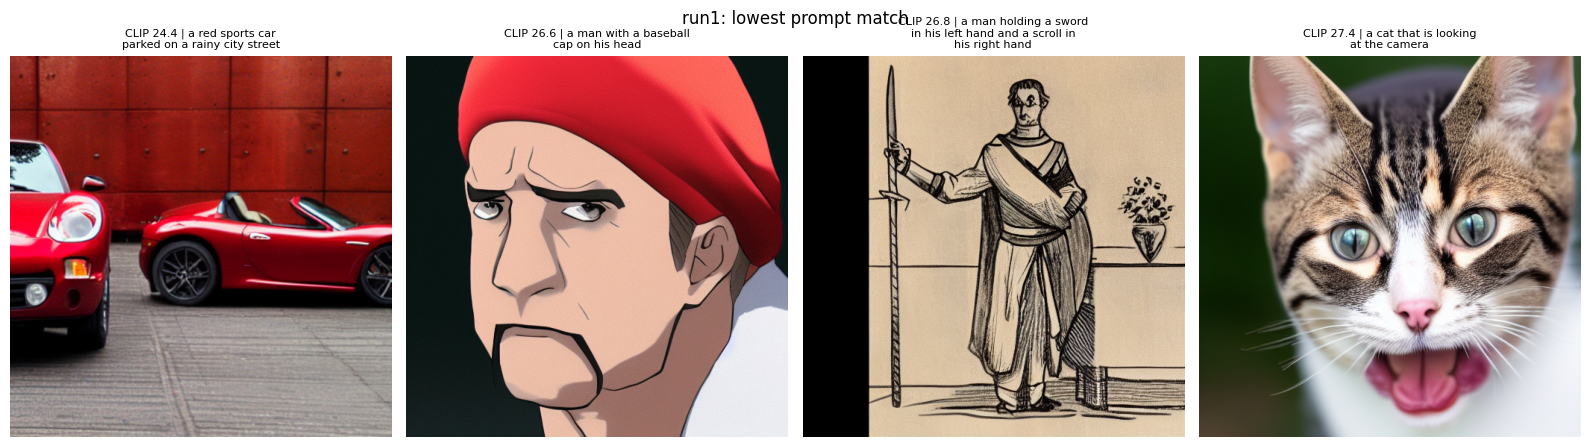

In [46]:
worst = gen.nsmallest(4, "clip")
fig, axes = plt.subplots(1, 4, figsize=(16, 4.6))
for ax, row in zip(axes, worst.itertuples()):
    ax.imshow(Image.open(row.file))
    ax.axis("off")
    ax.set_title(textwrap.fill(f"CLIP {row.clip:.1f} | {row.prompt}", 34), fontsize=8)
fig.suptitle(f"{RUN}: lowest prompt match")
plt.tight_layout()
plt.show()

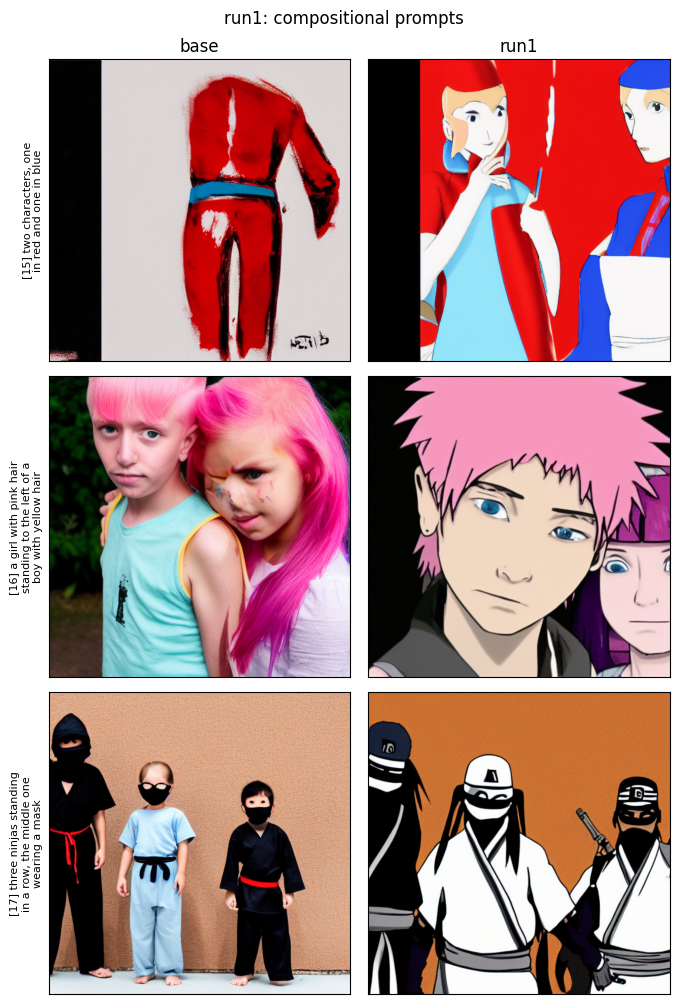

In [47]:
show_pairs([p["id"] for p in prompts if p["category"] == "compositional"][:3], title=f"{RUN}: compositional prompts")

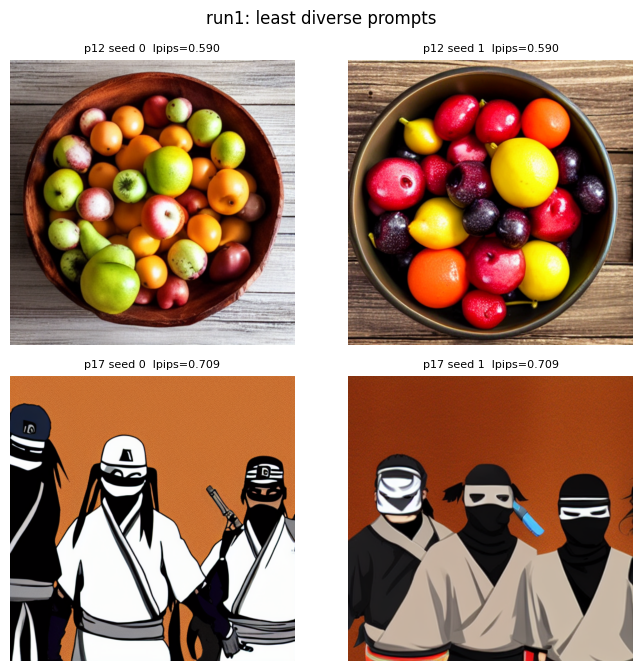

In [48]:
low = div.nsmallest(2, "lpips")
fig, axes = plt.subplots(len(low), 2, figsize=(7, 3.4 * len(low)))
for r, row in enumerate(low.itertuples()):
    for s in (0, 1):
        f = gen[(gen.prompt_id == row.prompt_id) & (gen.seed == s)].file.iloc[0]
        axes[r, s].imshow(Image.open(f))
        axes[r, s].axis("off")
        axes[r, s].set_title(f"p{row.prompt_id} seed {s}  lpips={row.lpips:.3f}", fontsize=8)
fig.suptitle(f"{RUN}: least diverse prompts")
plt.tight_layout()
plt.show()

**Run 1 observations** (write in your own words after looking at the images):
- ...
- ...

In [49]:
for f in [RUN_DIR / "pytorch_lora_weights.safetensors", RUN_DIR / "stats.json", EVAL / f"p2_{RUN}_training.csv",
          EVAL / f"p2_{RUN}_results.csv", GEN_DIR / f"{RUN}_metadata.csv", GEN_DIR / f"{RUN}_lpips.csv"]:
    print(f"{'ok ' if f.exists() else 'MISSING'}  {f}")

ok   /content/drive/MyDrive/data266-lab2/work/p2_runs/run1/pytorch_lora_weights.safetensors
ok   /content/drive/MyDrive/data266-lab2/work/p2_runs/run1/stats.json
ok   /content/drive/MyDrive/data266-lab2/eval/p2_run1_training.csv
ok   /content/drive/MyDrive/data266-lab2/eval/p2_run1_results.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_gen/run1_metadata.csv
ok   /content/drive/MyDrive/data266-lab2/work/p2_gen/run1_lpips.csv
